# NB5. Red de intercambio de minimo numero de unidades y red que respeta el pliegue

El caso continuo queda cerrado con una red de intercambio termico. Las curvas compuestas de NB1 fijan las metas del proceso, pero una meta de servicio no dice que unidades la alcanzan: eso lo resuelve la sintesis de red, que empareja corrientes calientes con corrientes frias y deja el resto a los servicios auxiliares.

Este cuaderno construye las dos redes de sintesis sobre el mismo caso. La red de minimo numero de unidades no persigue las metas del pliegue, de modo que lo cruza: empareja por geometria, ahorra un equipo y consume servicio en exceso. La red restringida al pliegue se construye contra las metas certificadas del motor y no puede transferir carga a traves del pliegue.

La segunda mitad audita el cierre de las dos ramas y dimensiona cada unidad con su diferencia media logaritmica. La cifra que resulta del conteo de unidades no es la misma que la cifra del costo de servicio: una red con una unidad menos puede consumir mas servicio y ocupar mas area.

In [4]:
# Public wheel asset of pre-release v0.2.1, verified by real download: 708503 bytes,
# SHA-256 60BBC0E65B558ACFB172E2522329216225CF8DAEB330225B1D35F564B329A605.
WHEEL_URL = "https://github.com/iwolde/ship-toolkit-releases/releases/download/v0.2.1/ship_toolkit-0.2.1-py3-none-any.whl"

_REQUIRED = "0.2.1"

import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    _version = importlib.metadata.version("ship-toolkit")
except importlib.metadata.PackageNotFoundError:
    _version = None

if importlib.util.find_spec("ship_toolkit") is None or (
    _version is not None and _version != _REQUIRED
):
    if not WHEEL_URL:
        raise RuntimeError("WHEEL_URL is empty: the wheel has not been published yet.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", WHEEL_URL], check=True)
    try:
        _version = importlib.metadata.version("ship-toolkit")
    except importlib.metadata.PackageNotFoundError:
        _version = None

if _version is None:
    import ship_toolkit
    _version = getattr(ship_toolkit, "__version__", "sin version")

print("ship-toolkit", _version)

ship-toolkit 0.2.1


## Como se ejecuta este cuaderno

En Colab la celda de preparacion instala el paquete desde el wheel de la pre-release cuando `WHEEL_URL` tiene valor.

Los datos llegan por `data_path` desde el paquete instalado. No se sube ningun archivo a mano y no se lee de Google Drive.

En ejecucion local desde el repositorio la celda de preparacion no instala nada.

In [6]:
from ship_toolkit import (
    apply_style,
    data_path,
    load_streams,
    plot_unit_transfer_table,
    run_pinch,
)
from ship_toolkit.hen_teaching import (
    area_m2,
    build_hen,
    build_slice_hens,
    closure_audit,
    dimension_units,
    lmtd_K,
    plot_grid_diagram,
    plot_slice_hens,
    plot_unified,
    unify_hens,
)

apply_style()

## El caso y los niveles de servicio declarados

El registro de corrientes es el caso continuo de la clase, el mismo de NB1. Sus metas de servicio se leen del motor Pinch con un acercamiento minimo de 10.0 K y una discretizacion de 5.0 K sobre el eje de temperatura.

Los dos niveles de servicio auxiliar se declaran en la llamada y no se heredan de un valor por defecto, porque el nivel de servicio es una decision de diseno de la planta. La red se sintetiza con servicio caliente de 250.0 C y servicio frio de 30.0 C, de modo que el servicio caliente queda por encima de todo objetivo de calentamiento y el servicio frio por debajo de todo objetivo de enfriamiento.

In [8]:
streams = load_streams(data_path("c53_continuous_streams.csv"))
result = run_pinch(streams, dT_min=10.0, dt_cont_K=5.0)

In [9]:
print("Metas del motor Pinch, caso continuo")
print(f"  servicio caliente minimo  {result.Qh_min_kW:.1f} kW")
print(f"  servicio frio minimo      {result.Qc_min_kW:.1f} kW")
print(f"  recuperacion interna      {result.Qr_kW:.1f} kW")
print(f"  pliegue corrido           {result.T_pinch_shifted_C:.1f} C")
print(f"  pliegue lado caliente     {result.T_pinch_hot_C:.1f} C")
print(f"  pliegue lado frio         {result.T_pinch_cold_C:.1f} C")

Metas del motor Pinch, caso continuo
  servicio caliente minimo  215.0 kW
  servicio frio minimo      32.0 kW
  recuperacion interna      1328.0 kW
  pliegue corrido           122.0 C
  pliegue lado caliente     127.0 C
  pliegue lado frio         117.0 C


## Las dos ramas de sintesis

La sintesis de red tiene dos criterios distintos y el cuaderno construye los dos sobre el mismo caso. El primero busca el minimo numero de unidades de transferencia y no persigue las metas del motor: su objetivo es reducir el conteo de equipos.

El segundo se construye con `respect_pinch=True` y queda restringido a las metas certificadas del motor Pinch, de modo que no puede transferir carga a traves del pliegue ni usar servicio frio sobre el pliegue o servicio caliente bajo el.

Las dos redes se construyen con los mismos niveles de servicio declarados, de modo que la diferencia entre sus cifras es el criterio de sintesis y no el servicio auxiliar.

In [11]:
network = build_hen(
    streams,
    result,
    t_hot_service_C=250.0,
    t_cold_service_C=30.0,
    respect_pinch=True,
)
network_unrestricted = build_hen(
    streams,
    result,
    t_hot_service_C=250.0,
    t_cold_service_C=30.0,
    respect_pinch=False,
)

In [12]:
print("Red con pliegue respetado")
print(f"  servicio caliente        {network.Qh_kW:.1f} kW")
print(f"  servicio frio            {network.Qc_kW:.1f} kW")
print(f"  cruce de pliegue         {network.cross_pinch_kW:.1f} kW")
print(f"  unidades                 {network.n_units}")
print(f"  carga apareada           {network.paired_kW:.1f} kW")
print(f"  unidades sobre el pliegue {network.n_units_above_pinch}")
print(f"  unidades bajo el pliegue  {network.n_units_below_pinch}")
print(f"  defecto de teselado      {network.closure_kW:.1e} kW")

Red con pliegue respetado
  servicio caliente        215.0 kW
  servicio frio            32.0 kW
  cruce de pliegue         0.0 kW
  unidades                 6
  carga apareada           1328.0 kW
  unidades sobre el pliegue 5
  unidades bajo el pliegue  1
  defecto de teselado      1.1e-13 kW


In [13]:
print("Red de minimo numero de unidades, sin restriccion de pliegue")
print(f"  servicio caliente   {network_unrestricted.Qh_kW:.1f} kW")
print(f"  servicio frio       {network_unrestricted.Qc_kW:.1f} kW")
print(f"  cruce de pliegue    {network_unrestricted.cross_pinch_kW:.1f} kW")
print(f"  unidades            {network_unrestricted.n_units}")
print(f"  carga apareada      {network_unrestricted.paired_kW:.1f} kW")
print(f"  defecto de teselado {network_unrestricted.closure_kW:.1e} kW")

Red de minimo numero de unidades, sin restriccion de pliegue
  servicio caliente   264.0 kW
  servicio frio       81.0 kW
  cruce de pliegue    49.0 kW
  unidades            5
  carga apareada      1279.0 kW
  defecto de teselado 1.1e-13 kW


## Lectura de las dos ramas

Las dos ramas no consumen lo mismo. La red sin restriccion consume 264.0 kW de servicio caliente frente a las 215.0 kW de la meta, y 81.0 kW de servicio frio frente a las 32.0 kW de la meta. El cruce de pliegue de 49.0 kW es exactamente el exceso de los dos servicios: la carga que atraviesa el pliegue se paga una vez en cada servicio.

Ese cruce es el precio de ignorar el pliegue. La red de minimo numero de unidades gana un equipo, cinco unidades frente a seis, y lo paga con 49.0 kW de servicio caliente, 49.0 kW de servicio frio y una carga apareada de 1279.0 kW que incluye el cruce, frente a los 1328.0 kW apareados por la red restringida.

La red con pliegue respetado ocupa una unidad mas y a cambio iguala las metas certificadas del motor: 215.0 kW de servicio caliente, 32.0 kW de servicio frio y cruce nulo.

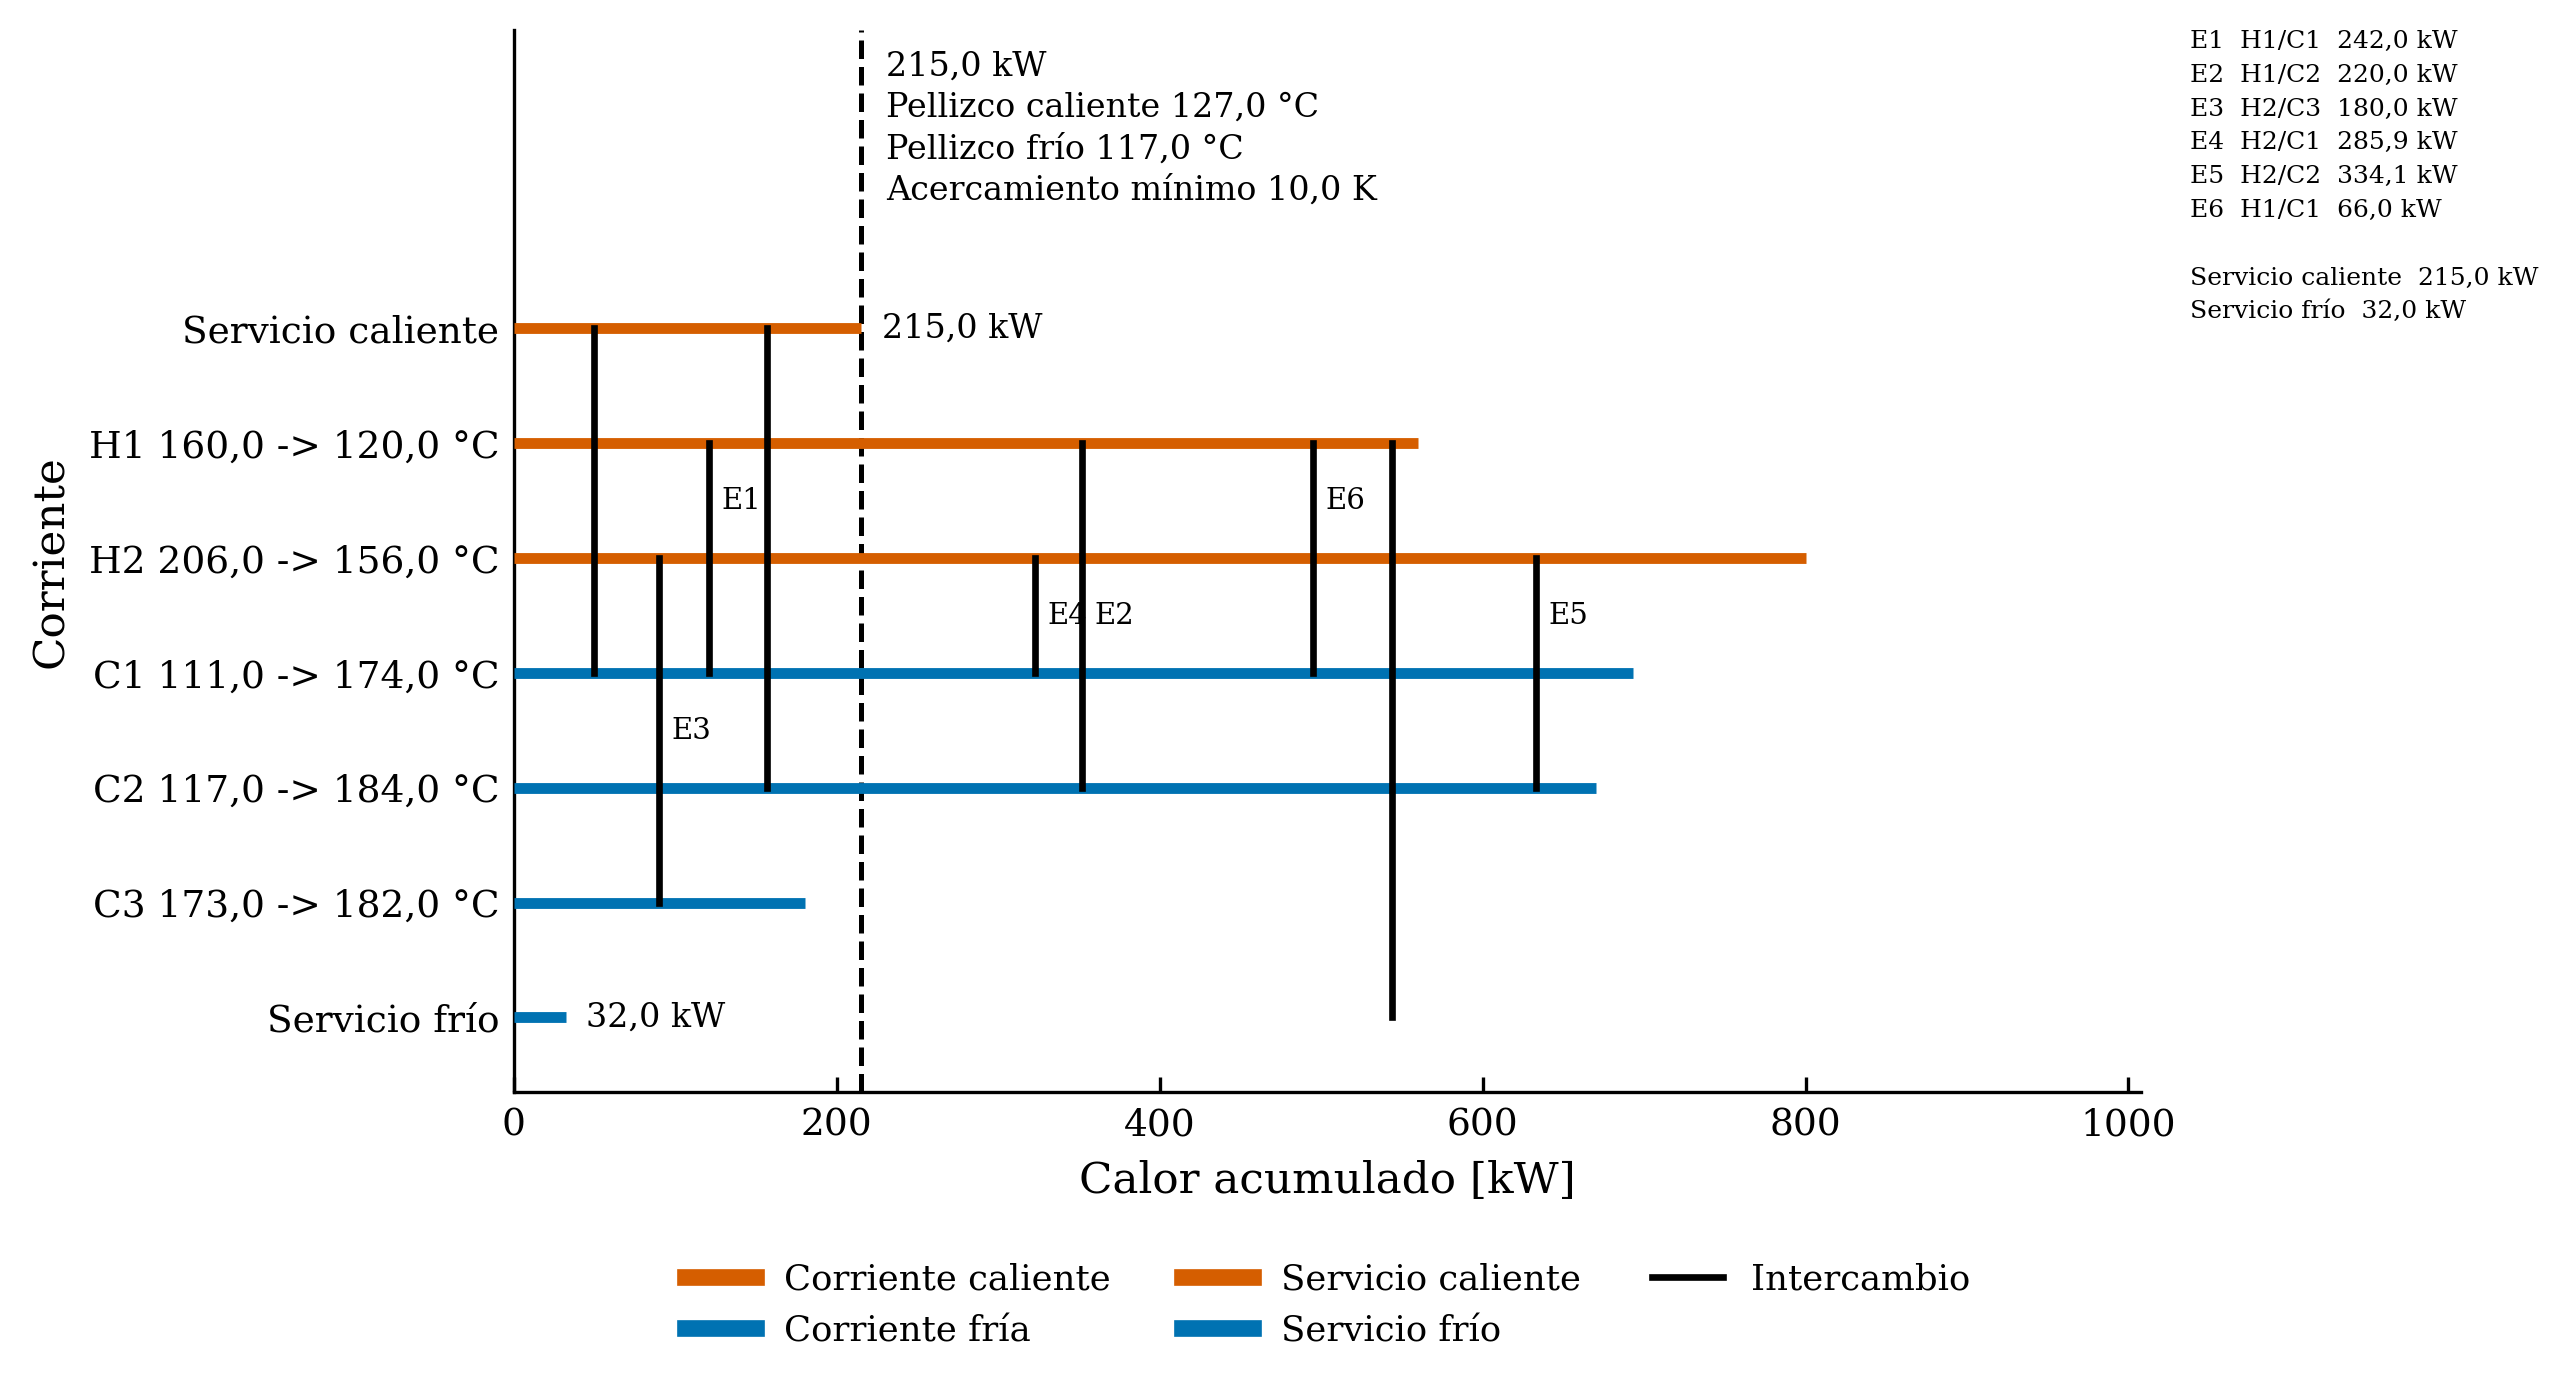

In [15]:
fig_grid = plot_grid_diagram(network.matches, streams, result)

## Redes por etapa y unificacion

La red por etapa es el registro que permite describir un proceso que cambia de corrientes en el tiempo. `build_slice_hens` recibe un diccionario de corrientes por etiqueta y devuelve una red por etapa con su propio consumo de servicio, su defecto de teselado y su cruce de pliegue.

En este cuaderno el proceso es continuo y por tanto hay una sola etapa, la etiqueta continuo, con las corrientes del caso continuo. El servicio auxiliar y el criterio de pliegue se declaran igual que en la sintesis directa.

`unify_hens` unifica las redes por etapa en una red de unidades compartidas y duplicadas. Con una sola etapa ninguna unidad es compartida entre etapas, pero la unificacion no se reduce a la lista de emparejamientos de la red: registra tambien las unidades de servicio auxiliar, de modo que su conteo de unidades y su conteo de instancias no coinciden con las seis unidades de la sintesis. El unico par de corrientes que intercambia calor en dos tramos distintos, H1 con C1, queda marcado como duplicado y aporta una instancia adicional.

In [17]:
slice_hens = build_slice_hens(
    {"continuo": streams},
    dT_min_K=10.0,
    t_hot_service_C=250.0,
    t_cold_service_C=30.0,
    respect_pinch=True,
)
unified = unify_hens(slice_hens)

In [18]:
print("Red unificada de una sola etapa")
print(f"  unidades compartidas  {unified.n_shared}")
print(f"  unidades duplicadas   {unified.n_duplicated}")
print(f"  instancias fisicas    {unified.n_instances}")
print("Unidades de la red unificada")
print("  clave  caliente  fria  carga_kW  reutilizada  duplicada")
for unidad_unificada in unified.units:
    print(
        f"  {unidad_unificada.key}"
        f"  {unidad_unificada.hot_name}"
        f"  {unidad_unificada.cold_name}"
        f"  {unidad_unificada.duty_kW:.1f}"
        f"  {unidad_unificada.reused}"
        f"  {unidad_unificada.duplicated}"
    )

Red unificada de una sola etapa
  unidades compartidas  0
  unidades duplicadas   1
  instancias fisicas    9
Unidades de la red unificada
  clave  caliente  fria  carga_kW  reutilizada  duplicada
  H1-C1  H1  C1  242.0  False  True
  H1-C2  H1  C2  220.0  False  False
  H2-C3  H2  C3  180.0  False  False
  H2-C1  H2  C1  285.9  False  False
  H2-C2  H2  C2  334.1  False  False
  HOT_SERVICE-C1  HOT_SERVICE  C1  99.1  False  False
  HOT_SERVICE-C2  HOT_SERVICE  C2  115.9  False  False
  H1-COLD_SERVICE  H1  COLD_SERVICE  32.0  False  False


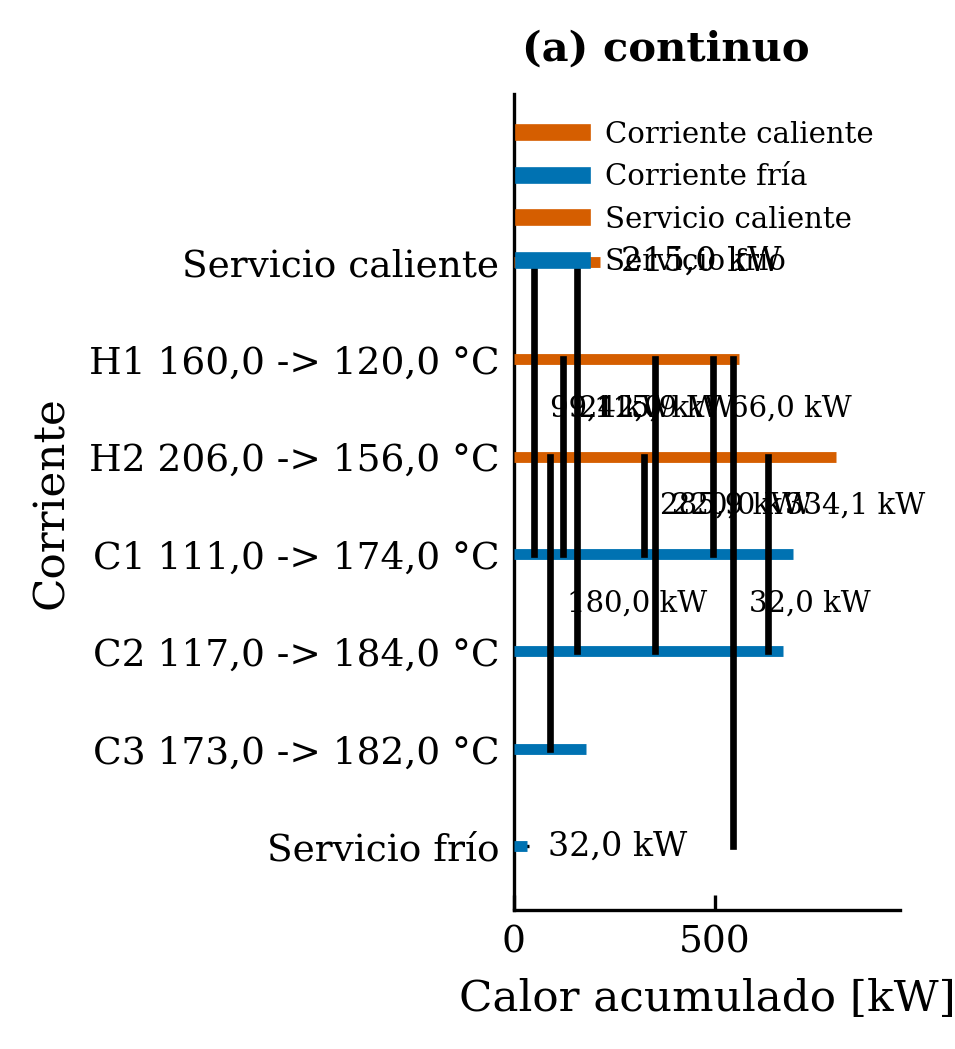

In [19]:
fig_slices = plot_slice_hens(slice_hens, stage_streams={"continuo": streams})

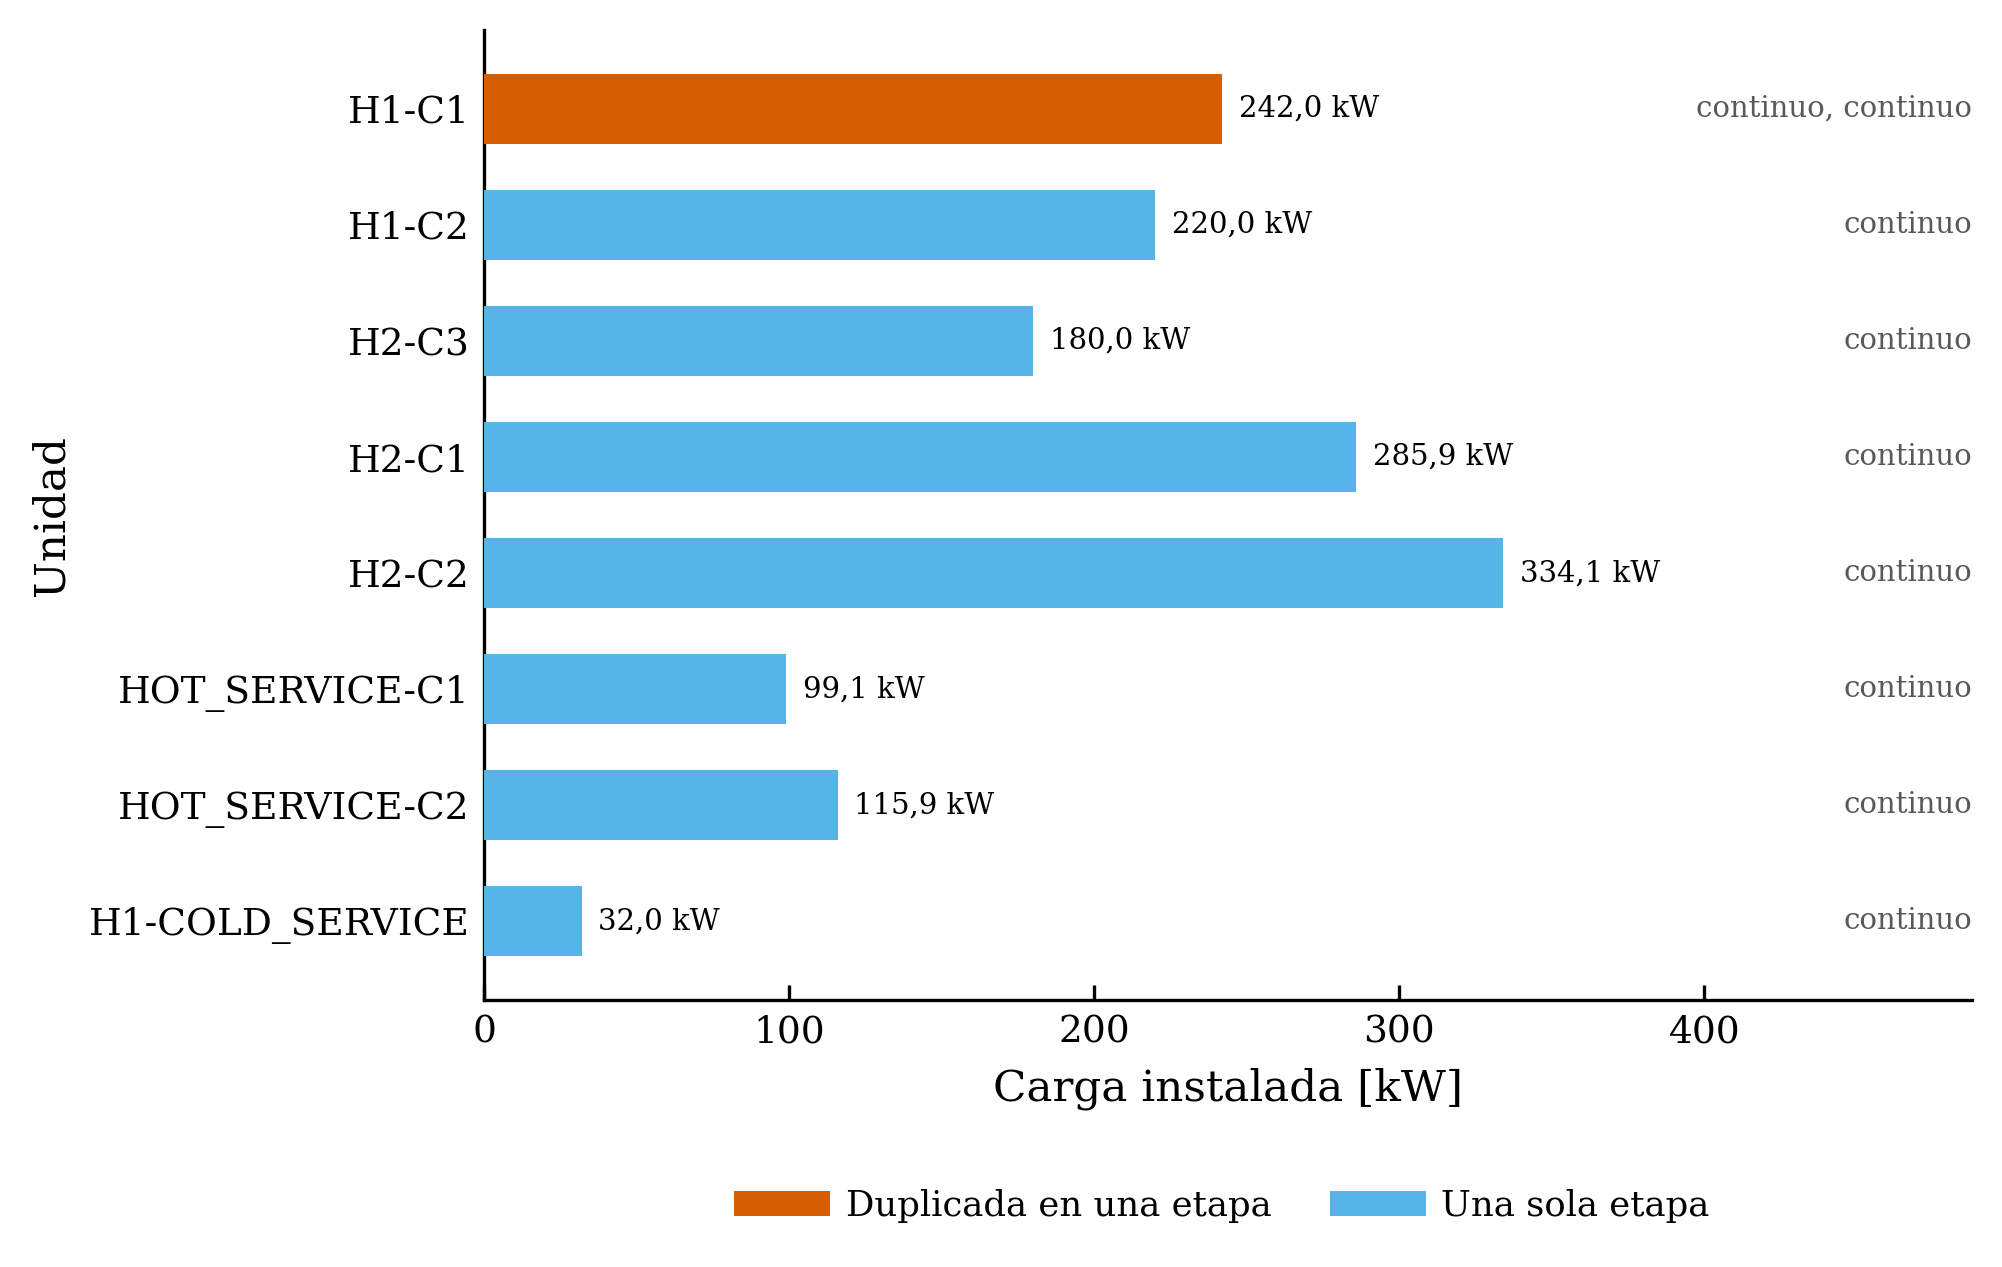

In [20]:
fig_unified = plot_unified(unified)

## Auditoria de cierre de las dos ramas

`closure_audit` compara la red contra las metas de un motor Pinch independiente del emparejamiento y devuelve un reporte con cuatro medidas evaluadas en valor absoluto contra una tolerancia.

La primera medida es el residuo de teselado de la red: el defecto geometrico del registro de intercambios, que mide la geometria del emparejamiento y no la consistencia global de la Primera Ley. Las otras dos son los residuos de servicio caliente y de servicio frio con signo, frente a las metas del motor. La cuarta es la carga transferida a traves del pliegue.

El indicador de cierre conjunto es verdadero solo cuando las cuatro medidas caben en la tolerancia. Un exceso de servicio o un cruce de pliegue lo vuelven falso aunque el teselado sea perfecto, de modo que la auditoria es falsable en las dos ramas.

In [22]:
report_closure = closure_audit(network, streams, tolerance_kW=1e-6)
report_closure_baseline = closure_audit(network_unrestricted, streams, tolerance_kW=1e-6)

In [23]:
print("Auditoria de cierre, red con pliegue respetado")
print(f"  residuo de teselado          {report_closure.residual_kW:.1e} kW")
print(f"  cierra                       {report_closure.closes}")
print(f"  tolerancia                   {report_closure.tolerance_kW:.1e} kW")
print(f"  residuo de servicio caliente {report_closure.heating_utility_residual_kW:.1f} kW")
print(f"  residuo de servicio frio     {report_closure.cooling_utility_residual_kW:.1f} kW")
print(f"  exceso de servicio caliente  {report_closure.heating_excess_kW:.1e} kW")
print(f"  exceso de servicio frio      {report_closure.cooling_excess_kW:.1e} kW")
print(f"  cruce de pliegue             {report_closure.cross_pinch_kW:.1f} kW")
print("Auditoria de cierre, red de minimo numero de unidades")
print(f"  residuo de teselado          {report_closure_baseline.residual_kW:.1e} kW")
print(f"  cierra                       {report_closure_baseline.closes}")
print(f"  tolerancia                   {report_closure_baseline.tolerance_kW:.1e} kW")
print(f"  residuo de servicio caliente {report_closure_baseline.heating_utility_residual_kW:.1f} kW")
print(f"  residuo de servicio frio     {report_closure_baseline.cooling_utility_residual_kW:.1f} kW")
print(f"  exceso de servicio caliente  {report_closure_baseline.heating_excess_kW:.1e} kW")
print(f"  exceso de servicio frio      {report_closure_baseline.cooling_excess_kW:.1e} kW")
print(f"  cruce de pliegue             {report_closure_baseline.cross_pinch_kW:.1f} kW")

Auditoria de cierre, red con pliegue respetado
  residuo de teselado          1.1e-13 kW
  cierra                       True
  tolerancia                   1.0e-06 kW
  residuo de servicio caliente 0.0 kW
  residuo de servicio frio     0.0 kW
  exceso de servicio caliente  8.5e-14 kW
  exceso de servicio frio      8.5e-14 kW
  cruce de pliegue             0.0 kW
Auditoria de cierre, red de minimo numero de unidades
  residuo de teselado          1.1e-13 kW
  cierra                       False
  tolerancia                   1.0e-06 kW
  residuo de servicio caliente 49.0 kW
  residuo de servicio frio     49.0 kW
  exceso de servicio caliente  4.9e+01 kW
  exceso de servicio frio      4.9e+01 kW
  cruce de pliegue             49.0 kW


## Dimensionamiento de las unidades

Una red sintetizada no esta dimensionada: el emparejamiento fija que corrientes se tocan y con que carga, pero no cuanto area exige cada unidad. El area sale de la carga, del coeficiente global declarado y de la diferencia media logaritmica de temperatura de la unidad.

`lmtd_K` calcula la diferencia media logaritmica a partir de los dos extremos de la unidad y resuelve el limite de extremos iguales sin dividir por cero. `area_m2` aplica la identidad de transferencia sobre la carga, la LMTD y el coeficiente global.

`dimension_units` recibe la red completa y no su lista de emparejamientos, de modo que conserva el orden y los conteos de la red. Cada unidad dimensionada porta sus dos extremos, su LMTD, el coeficiente global aplicado y su area. El area total es un campo del reporte y el coeficiente global declarado tambien, de modo que ninguna de las dos cifras queda implicita en la celda.

El dimensionamiento se aplica a las dos ramas con el mismo coeficiente global declarado, de modo que la comparacion de areas es una comparacion de geometria de red y no de coeficiente.

In [25]:
delta_T_ml = lmtd_K(dT_in_K=60.0, dT_out_K=40.0)
area_unidad_m2 = area_m2(duty_kW=120.0, lmtd_K=delta_T_ml, U_kW_per_m2K=0.8)
report_dim = dimension_units(network=network, U_kW_per_m2K=0.8)
report_dim_baseline = dimension_units(network=network_unrestricted, U_kW_per_m2K=0.8)

In [26]:
print("Diferencia media logaritmica y area de una unidad de referencia")
print(f"  LMTD de extremos 60.0 K y 40.0 K  {delta_T_ml:.6f} K")
print(f"  area de 120.0 kW con U 0.8        {area_unidad_m2:.6f} m2")
print("Dimensionamiento de la red con pliegue respetado")
print(f"  area total                        {report_dim.total_area_m2:.6f} m2")
print(f"  coeficiente global declarado      {report_dim.declared_U_kW_per_m2K:.1f} kW/(m2 K)")
print(f"  area total sin restriccion        {report_dim_baseline.total_area_m2:.6f} m2")
print("  caliente  fria  carga_kW  dT_in_K  dT_out_K  LMTD_K  U  area_m2")
for unidad_transferencia in report_dim.units:
    print(
        f"  {unidad_transferencia.hot_name}"
        f"  {unidad_transferencia.cold_name}"
        f"  {unidad_transferencia.duty_kW:.1f}"
        f"  {unidad_transferencia.dT_in_K:.1f}"
        f"  {unidad_transferencia.dT_out_K:.1f}"
        f"  {unidad_transferencia.lmtd_K:.6f}"
        f"  {unidad_transferencia.U_kW_per_m2K:.1f}"
        f"  {unidad_transferencia.area_m2:.6f}"
    )

Diferencia media logaritmica y area de una unidad de referencia
  LMTD de extremos 60.0 K y 40.0 K  49.326069 K
  area de 120.0 kW con U 0.8        3.040988 m2
Dimensionamiento de la red con pliegue respetado
  area total                        93.604402 m2
  coeficiente global declarado      0.8 kW/(m2 K)
  area total sin restriccion        97.585169 m2
  caliente  fria  carga_kW  dT_in_K  dT_out_K  LMTD_K  U  area_m2
  H1  C1  242.0  21.0  10.0  14.826050  0.8  20.403277
  H1  C2  220.0  21.0  10.0  14.826050  0.8  18.548434
  H2  C3  180.0  24.0  21.8  22.856545  0.8  9.844007
  H2  C1  285.9  29.8  17.0  22.788500  0.8  15.680511
  H2  C2  334.1  22.3  17.0  19.547141  0.8  21.367047
  H1  C1  66.0  10.0  11.3  10.629901  0.8  7.761126


In [27]:
unidad = report_dim.units[0]
print("Primera unidad de la red dimensionada")
print(f"  corriente caliente   {unidad.hot_name}")
print(f"  corriente fria       {unidad.cold_name}")
print(f"  carga                {unidad.duty_kW:.1f} kW")
print(f"  extremo de entrada   {unidad.dT_in_K:.1f} K")
print(f"  extremo de salida    {unidad.dT_out_K:.1f} K")
print(f"  LMTD                 {unidad.lmtd_K:.6f} K")
print(f"  coeficiente global   {unidad.U_kW_per_m2K:.1f} kW/(m2 K)")
print(f"  area                 {unidad.area_m2:.6f} m2")

Primera unidad de la red dimensionada
  corriente caliente   H1
  corriente fria       C1
  carga                242.0 kW
  extremo de entrada   21.0 K
  extremo de salida    10.0 K
  LMTD                 14.826050 K
  coeficiente global   0.8 kW/(m2 K)
  area                 20.403277 m2


## Que muestra la tabla de unidades

La tabla dibuja una fila por unidad, seis en total, con el par de corrientes, la carga, los dos extremos, la LMTD, el coeficiente global aplicado y el area requerida. El area total del conjunto es 93.604402 m2.

La LMTD menor de la red es 10.629901 K, que queda por encima del acercamiento minimo de 10.0 K declarado en el motor. Ninguna unidad de la red restringida opera por debajo del acercamiento, de modo que todas son factibles con el pliegue respetado.

Cada area de la tabla satisface la identidad de transferencia con la carga, la LMTD y el coeficiente global impresos en su propia fila. El area total es el area de las seis unidades y no una cota ni una estimacion.

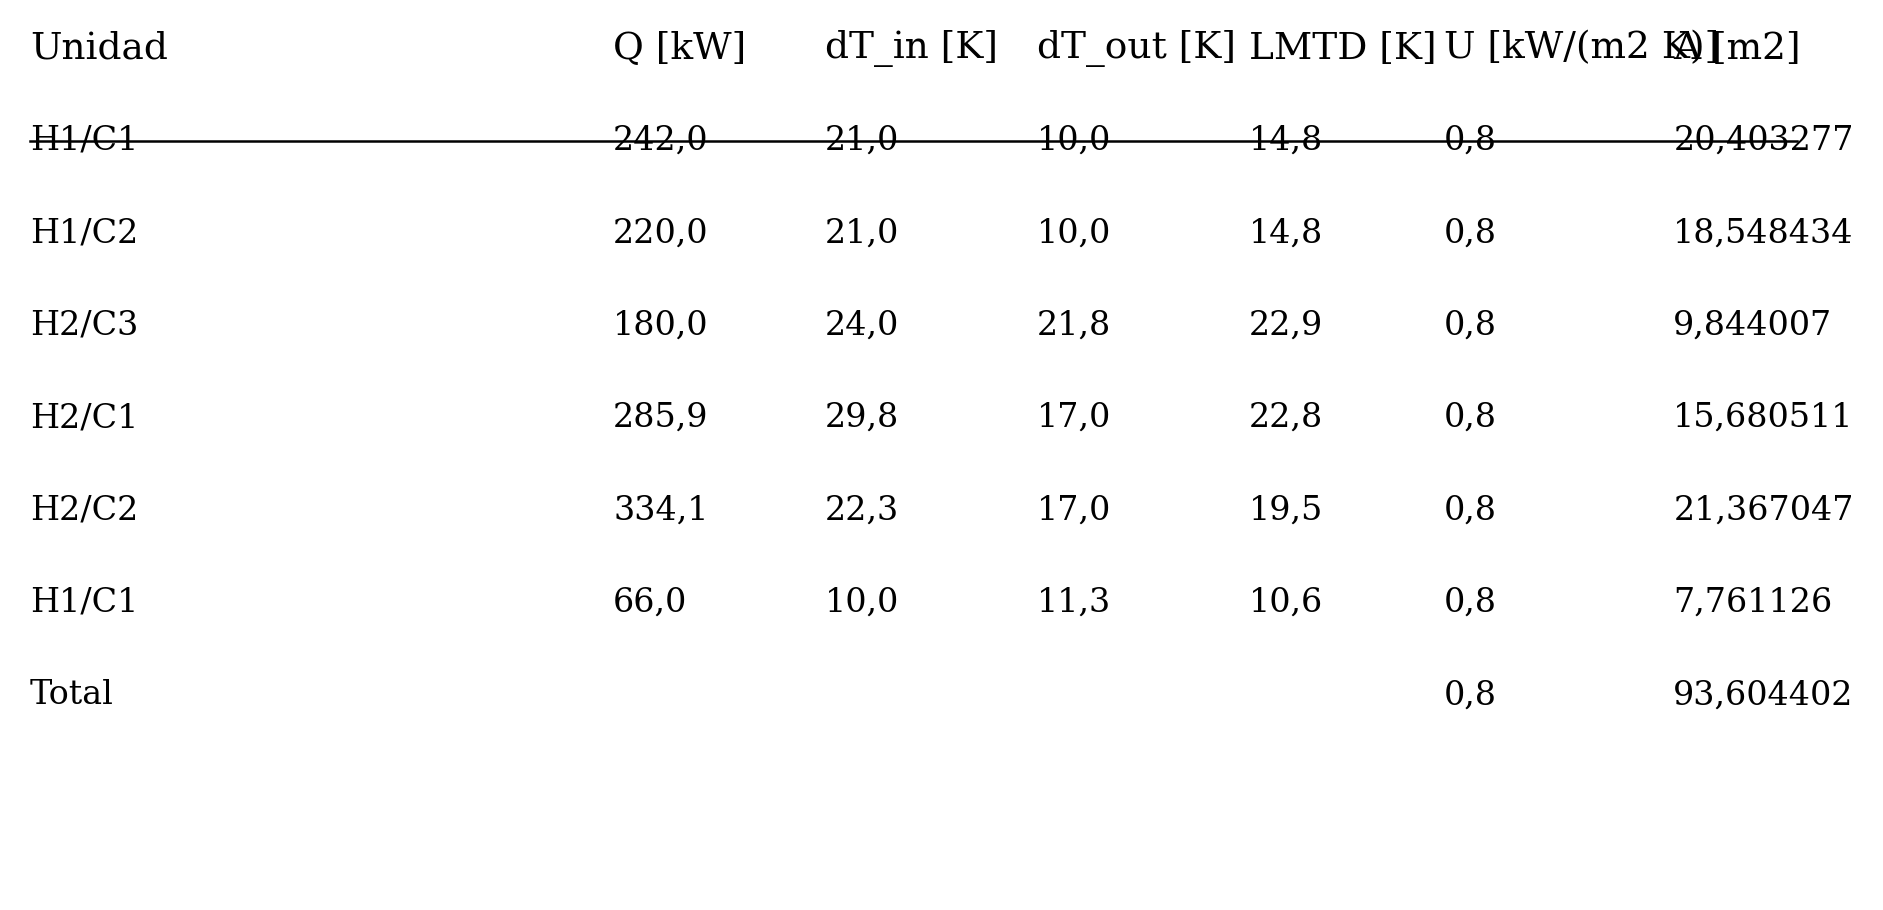

In [29]:
fig_units = plot_unit_transfer_table(report_dim)

## Que ensena este cuaderno

La red de minimo numero de unidades no es la red de minimo costo. Ahorra una unidad, cinco equipos frente a seis, y lo paga con 49.0 kW de servicio caliente y 49.0 kW de servicio frio sobre las metas certificadas, con un cruce de pliegue de 49.0 kW que la auditoria de cierre declara como no cerrado.

El area acompania ese resultado: la rama sin restriccion mide 97.585169 m2 frente a los 93.604402 m2 que entrega el dimensionamiento de esta red, de modo que el ahorro de un equipo se paga ademas en superficie de transferencia.

La red que respeta el pliegue iguala las metas certificadas del motor, 215.0 kW de servicio caliente y 32.0 kW de servicio frio sin cruce, y su area es la que sostiene el dimensionamiento de cada una de sus seis unidades. La decision de diseno no se reduce al conteo de equipos: el numero de unidades y el costo de servicio son dos cifras distintas y el cuaderno las mide por separado.